# Introduction to PyTorch

You've written a lot of code in this assignment to provide a whole host of neural network functionality. Dropout, Batch Norm, and 2D convolutions are some of the workhorses of deep learning in computer vision. You've also worked hard to make your code efficient and vectorized.

For the last part of this assignment, though, we're going to leave behind your beautiful codebase and instead migrate to PyTorch, the most widely used deep learning framework in research and in medical imaging.

## Why do we use deep learning frameworks?

* Our code will now run on GPUs! This will allow our models to train much faster. When using a framework like PyTorch you can harness the power of the GPU for your own custom neural network architectures without having to write CUDA code directly (which is beyond the scope of this class).
* In this class, we want you to be ready to use one of these frameworks for your project so you can experiment more efficiently than if you were writing every feature you want to use by hand.
* We want you to stand on the shoulders of giants! PyTorch is an excellent framework that will make your lives a lot easier, and now that you understand their guts, you are free to use them :)
* Finally, we want you to be exposed to the sort of deep learning code you might run into in academia or industry.

## What is PyTorch?

PyTorch is a system for executing dynamic computational graphs over Tensor objects that behave similarly to NumPy arrays. It comes with a powerful automatic differentiation engine that removes the need for manual back-propagation.

## How do I learn PyTorch?
Here are some online resources for getting familiar with PyTorch:
* [The official PyTorch tutorials ("Learn the Basics")](https://docs.pytorch.org/tutorials/beginner/basics/intro.html)
* [https://github.com/jcjohnson/pytorch-examples](https://github.com/jcjohnson/pytorch-examples)
* [https://www.youtube.com/watch?v=2S1dgHpqCdk&list=PLhhyoLH6IjfxeoooqP9rhU3HJIAVAJ3Vz](https://www.youtube.com/watch?v=2S1dgHpqCdk&list=PLhhyoLH6IjfxeoooqP9rhU3HJIAVAJ3Vz)
* [https://www.youtube.com/watch?v=EMXfZB8FVUA&list=PLqnslRFeH2UrcDBWF5mfPGpqQDSta6VK4](https://www.youtube.com/watch?v=EMXfZB8FVUA&list=PLqnslRFeH2UrcDBWF5mfPGpqQDSta6VK4)

You can also find the detailed [API documentation](https://docs.pytorch.org/docs/stable/index.html) here. If you have other questions that are not addressed by the API docs, the [PyTorch forum](https://discuss.pytorch.org/) is a good place to ask.

# Table of Contents

This assignment has 6 parts. You will learn PyTorch on **three different levels of abstraction**, which will help you understand it better and prepare you for the final project.

1. Part I, Preparation: we will use the PneumoniaMNIST dataset.
2. Part II, Barebones PyTorch: **Abstraction level 1**, we will work directly with the lowest-level PyTorch Tensors.
3. Part III, PyTorch Module API: **Abstraction level 2**, we will use `nn.Module` to define arbitrary neural network architecture.
4. Part IV, PyTorch Sequential API: **Abstraction level 3**, we will use `nn.Sequential` to define a linear feed-forward network very conveniently.
5. Part V, Training and evaluating a model properly: reproducibility, metrics for imbalanced medical data, loss curves, checkpointing the best model, learning-rate schedules and mixed precision.
6. Part VI, open-ended challenge: please implement your own network to get as high performance as possible on PneumoniaMNIST. You can experiment with any layer, optimizer, hyperparameters or other advanced features.

Here is a table of comparison:

| API           | Flexibility | Convenience |
|---------------|-------------|-------------|
| Barebone      | High        | Low         |
| `nn.Module`     | High        | Medium      |
| `nn.Sequential` | Low         | High        |

# GPU

The cell below uses a GPU if one is available, and otherwise falls back to the CPU:

* **On MAIA**, your workspace has an NVIDIA GPU (unless your group has a CPU-only workspace), and you should see `using device: cuda`.
* **On an Apple-silicon Mac**, PyTorch can use the built-in GPU (`using device: mps`).
* **On the CPU**, everything in this notebook still works, it is just slower.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F  # useful stateless functions
import torch.optim as optim
from torch.utils.data import DataLoader

import torchvision.transforms as T

import numpy as np

USE_GPU = True
dtype = torch.float32 # We will be using float throughout this tutorial.

if USE_GPU and torch.cuda.is_available():
    device = torch.device('cuda')
elif USE_GPU and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

# Constant to control how frequently (in iterations) we print the train loss.
# One epoch of PneumoniaMNIST is 74 iterations of 64 images.
print_every = 25
print('using device:', device)

using device: cpu


# Part I. Preparation

We will use [PneumoniaMNIST](https://medmnist.com/), one of the MedMNIST datasets: 28x28 grayscale chest X-ray images, each labelled as normal (`0`) or pneumonia (`1`). This is a **binary** classification problem, so our networks will output a single score (a logit) per image instead of one score per class.

The `medmnist` package downloads the dataset into `cm2003/datasets/` the first time (about 4 MB), unless you already ran `python download_data.py`.

In [2]:
# The torchvision.transforms package provides tools for preprocessing data
# and for performing data augmentation. Here we set up a transform to
# preprocess the data by subtracting the mean pixel value and dividing by the
# standard deviation; we've hardcoded the mean and std of the training set.
# The images are grayscale, so there is only one channel.
transform = T.Compose([
                T.ToTensor(),
                T.Normalize((0.5719,), (0.1684,))
            ])

# Load the PneumoniaMNIST dataset (train / validation / test splits). The whole dataset fits
# in memory, so we load batches in the main process (num_workers=0).
from medmnist import PneumoniaMNIST
dataset_train = PneumoniaMNIST(root='cm2003/datasets', split='train', transform=transform, download=True)
loader_train = DataLoader(dataset_train, batch_size=64, shuffle=True, num_workers=0)

dataset_val = PneumoniaMNIST(root='cm2003/datasets', split='val', transform=transform, download=True)
loader_val = DataLoader(dataset_val, batch_size=64, shuffle=False, num_workers=0)

dataset_test = PneumoniaMNIST(root='cm2003/datasets', split='test', transform=transform, download=True)
loader_test = DataLoader(dataset_test, batch_size=64, shuffle=False, num_workers=0)

for name, ds in [('train', dataset_train), ('val', dataset_val), ('test', dataset_test)]:
    labels = ds.labels.flatten()
    print(f'{name}: {len(ds)} images, {100 * labels.mean():.1f}% pneumonia')

train: 4708 images, 74.2% pneumonia
val: 524 images, 74.2% pneumonia
test: 624 images, 62.5% pneumonia


In [3]:
# After our normalization the training images have mean 0 and std 1
x_sum = 0
x_squared_sum = 0
num = 0

for x, y in loader_train:
    x_sum += x.sum()
    x_squared_sum += (x ** 2).sum()
    num += x.numel()

mean = x_sum / num
variance = (x_squared_sum / num) - (mean ** 2)
std_dev = torch.sqrt(variance)

print(f'Mean: {mean:.4f}')
print(f'Standard Deviation: {std_dev:.4f}')

Mean: 0.0001
Standard Deviation: 0.9997


### Note on accuracy

About 74% of the training and validation images show pneumonia, so a "model" that always answers *pneumonia* already gets about 74% accuracy on the validation set. Keep this baseline in mind when you look at the accuracies below: a useful model has to do clearly better than that.

# Part II. Barebones PyTorch

PyTorch ships with high-level APIs to help us define model architectures conveniently, which we will cover in Parts III and IV of this tutorial. In this section, we will start with the barebone PyTorch elements to understand the autograd engine better. After this exercise, you will come to appreciate the high-level model API more.

We will start with a simple fully-connected ReLU network with one hidden layer and no biases for PneumoniaMNIST classification.
This implementation computes the forward pass using operations on PyTorch Tensors, and uses PyTorch autograd to compute gradients. It is important that you understand every line, because you will write a harder version after the example.

When we create a PyTorch Tensor with `requires_grad=True`, then operations involving that Tensor will not just compute values; they will also build up a computational graph in the background, allowing us to easily backpropagate through the graph to compute gradients of some Tensors with respect to a downstream loss. Concretely if x is a Tensor with `x.requires_grad == True` then after backpropagation `x.grad` will be another Tensor holding the gradient of x with respect to the scalar loss at the end.

### PyTorch Tensors: Flatten Function
A PyTorch Tensor is conceptually similar to a NumPy array: it is an n-dimensional grid of numbers, and like numpy PyTorch provides many functions to efficiently operate on Tensors. As a simple example, we provide a `flatten` function below which reshapes image data for use in a fully-connected neural network.

Recall that image data is typically stored in a Tensor of shape N x C x H x W, where:

* N is the number of datapoints
* C is the number of channels
* H is the height of the intermediate feature map in pixels
* W is the width of the intermediate feature map in pixels

This is the right way to represent the data when we are doing something like a 2D convolution, that needs spatial understanding of where the intermediate features are relative to each other. When we use fully connected affine layers to process the image, however, we want each datapoint to be represented by a single vector -- it's no longer useful to segregate the different channels, rows, and columns of the data. So, we use a "flatten" operation to collapse the `C x H x W` values per representation into a single long vector. The flatten function below first reads in the N, C, H, and W values from a given batch of data, and then returns a "view" of that data. "View" is analogous to numpy's "reshape" method: it reshapes x's dimensions to be N x ??, where ?? is allowed to be anything (in this case, it will be C x H x W, but we don't need to specify that explicitly). 

In [4]:
def flatten(x):
    N = x.shape[0] # read in N, C, H, W
    return x.view(N, -1)  # "flatten" the C * H * W values into a single vector per image

def test_flatten():
    x = torch.arange(12).view(2, 1, 3, 2)
    print('Before flattening: ', x)
    print('After flattening: ', flatten(x))

test_flatten()

Before flattening:  tensor([[[[ 0,  1],
          [ 2,  3],
          [ 4,  5]]],


        [[[ 6,  7],
          [ 8,  9],
          [10, 11]]]])
After flattening:  tensor([[ 0,  1,  2,  3,  4,  5],
        [ 6,  7,  8,  9, 10, 11]])


### Barebones PyTorch: Two-Layer Network

Here we define a function `two_layer_fc` which performs the forward pass of a two-layer fully-connected ReLU network on a batch of image data. After defining the forward pass we check that it doesn't crash and that it produces outputs of the right shape by running zeros through the network.

You don't have to write any code here, but it's important that you read and understand the implementation.

In [5]:
def two_layer_fc(x, params):
    """
    A fully-connected neural networks; the architecture is:
    NN is fully connected -> ReLU -> fully connected layer.
    Note that this function only defines the forward pass; 
    PyTorch will take care of the backward pass for us.
    
    The input to the network will be a minibatch of data, of shape
    (N, d1, ..., dM) where d1 * ... * dM = D. The hidden layer will have H units,
    and the output layer will produce C scores (C = 1 for our binary problem).
    
    Inputs:
    - x: A PyTorch Tensor of shape (N, d1, ..., dM) giving a minibatch of
      input data.
    - params: A list [w1, w2] of PyTorch Tensors giving weights for the network;
      w1 has shape (D, H) and w2 has shape (H, C).
    
    Returns:
    - scores: A PyTorch Tensor of shape (N, C) giving classification scores for
      the input data x.
    """
    # first we flatten the image
    x = flatten(x)  # shape: [batch_size, C x H x W]
    
    w1, w2 = params
    
    # Forward pass: compute predicted y using operations on Tensors. Since w1 and
    # w2 have requires_grad=True, operations involving these Tensors will cause
    # PyTorch to build a computational graph, allowing automatic computation of
    # gradients. Since we are no longer implementing the backward pass by hand we
    # don't need to keep references to intermediate values.
    # you can also use `.clamp(min=0)`, equivalent to F.relu()
    x = F.relu(x.mm(w1))
    x = x.mm(w2)
    return x
    

def two_layer_fc_test():
    hidden_layer_size = 42
    x = torch.zeros((64, 50), dtype=dtype)  # minibatch size 64, feature dimension 50
    w1 = torch.zeros((50, hidden_layer_size), dtype=dtype)
    w2 = torch.zeros((hidden_layer_size, 1), dtype=dtype)
    scores = two_layer_fc(x, [w1, w2])
    print(scores.size())  # you should see [64, 1]

two_layer_fc_test()

torch.Size([64, 1])


### Barebones PyTorch: Three-Layer ConvNet

Here you will complete the implementation of the function `three_layer_convnet`, which will perform the forward pass of a three-layer convolutional network. Like above, we can immediately test our implementation by passing zeros through the network. The network should have the following architecture:

1. A convolutional layer (with bias) with `channel_1` filters, each with shape `KW1 x KH1`, and zero-padding of two
2. ReLU nonlinearity
3. A convolutional layer (with bias) with `channel_2` filters, each with shape `KW2 x KH2`, and zero-padding of one
4. ReLU nonlinearity
5. Fully-connected layer with bias, producing a single score (logit) per image.

Note that we have **no sigmoid activation** here after our fully-connected layer: this is because PyTorch's `F.binary_cross_entropy_with_logits` applies the sigmoid for you, and bundling that step into the loss is numerically more stable.

**HINT**: For convolutions: https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.conv2d.html; pay attention to the shapes of convolutional filters!

In [6]:
def three_layer_convnet(x, params):
    """
    Performs the forward pass of a three-layer convolutional network with the
    architecture defined above.

    Inputs:
    - x: A PyTorch Tensor of shape (N, 1, H, W) giving a minibatch of images
    - params: A list of PyTorch Tensors giving the weights and biases for the
      network; should contain the following:
      - conv_w1: PyTorch Tensor of shape (channel_1, 1, KH1, KW1) giving weights
        for the first convolutional layer
      - conv_b1: PyTorch Tensor of shape (channel_1,) giving biases for the first
        convolutional layer
      - conv_w2: PyTorch Tensor of shape (channel_2, channel_1, KH2, KW2) giving
        weights for the second convolutional layer
      - conv_b2: PyTorch Tensor of shape (channel_2,) giving biases for the second
        convolutional layer
      - fc_w: PyTorch Tensor giving weights for the fully-connected layer. Can you
        figure out what the shape should be?
      - fc_b: PyTorch Tensor giving biases for the fully-connected layer. Can you
        figure out what the shape should be?
    
    Returns:
    - scores: PyTorch Tensor of shape (N, 1) giving a classification score (logit) for each image in x
    """
    conv_w1, conv_b1, conv_w2, conv_b2, fc_w, fc_b = params
    scores = None
    ################################################################################
    # TODO: Implement the forward pass for the three-layer ConvNet.                #
    ################################################################################
    # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

    scores= F.conv2d(x,conv_w1,conv_b1,padding=2)
    scores=F.relu(scores)
    scores=F.conv2d(scores,conv_w2,conv_b2,padding=1)
    scores=F.relu(scores)
    scores=flatten(scores)
    scores=scores.mm(fc_w)+fc_b

    # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
    ################################################################################
    #                                 END OF YOUR CODE                             #
    ################################################################################
    return scores

After defining the forward pass of the ConvNet above, run the following cell to test your implementation.

When you run this function, scores should have shape (64, 1).

In [7]:
def three_layer_convnet_test():
    x = torch.zeros((64, 1, 28, 28), dtype=dtype)  # minibatch size 64, image size [1, 28, 28]

    conv_w1 = torch.zeros((6, 1, 5, 5), dtype=dtype)  # [out_channel, in_channel, kernel_H, kernel_W]
    conv_b1 = torch.zeros((6,))  # out_channel
    conv_w2 = torch.zeros((9, 6, 3, 3), dtype=dtype)  # [out_channel, in_channel, kernel_H, kernel_W]
    conv_b2 = torch.zeros((9,))  # out_channel

    # you must calculate the shape of the tensor after two conv layers, before the fully-connected layer
    fc_w = torch.zeros((9 * 28 * 28, 1))
    fc_b = torch.zeros(1)

    scores = three_layer_convnet(x, [conv_w1, conv_b1, conv_w2, conv_b2, fc_w, fc_b])
    print(scores.size())  # you should see [64, 1]
three_layer_convnet_test()

torch.Size([64, 1])


### Barebones PyTorch: Initialization
Let's write a couple utility methods to initialize the weight matrices for our models.

- `random_weight(shape)` initializes a weight tensor with the Kaiming normalization method.
- `zero_weight(shape)` initializes a weight tensor with all zeros. Useful for instantiating bias parameters.

The `random_weight` function uses the Kaiming normal initialization method, described in:

He et al, *Delving Deep into Rectifiers: Surpassing Human-Level Performance on ImageNet Classification*, ICCV 2015, https://arxiv.org/abs/1502.01852

In [8]:
def random_weight(shape):
    """
    Create random Tensors for weights; setting requires_grad=True means that we
    want to compute gradients for these Tensors during the backward pass.
    We use Kaiming normalization: sqrt(2 / fan_in)
    """
    if len(shape) == 2:  # FC weight
        fan_in = shape[0]
    else:
        fan_in = np.prod(shape[1:]) # conv weight [out_channel, in_channel, kH, kW]
    # randn is standard normal distribution generator. 
    w = torch.randn(shape, device=device, dtype=dtype) * np.sqrt(2. / fan_in)
    w.requires_grad = True
    return w

def zero_weight(shape):
    return torch.zeros(shape, device=device, dtype=dtype, requires_grad=True)

# create a weight of shape [3 x 5]
# you should see device='cuda:0' (or 'mps:0') if you use a GPU.
random_weight((3, 5))

tensor([[-0.8911,  0.6505,  0.0443,  0.9665, -1.1626],
        [-0.3384,  0.5238, -0.8219, -0.3083,  0.6158],
        [-0.0954,  0.7236,  0.7517, -0.3960, -0.0049]], requires_grad=True)

### Barebones PyTorch: Check Accuracy
When training the model we will use the following function to check the accuracy of our model on the training or validation sets.

The network outputs a logit (score) per image; the predicted probability of pneumonia is `sigmoid(score)`. We predict *pneumonia* when that probability is at least 0.5, which is the same as `score >= 0`.

When checking accuracy we don't need to compute any gradients; as a result we don't need PyTorch to build a computational graph for us when we compute scores. To prevent a graph from being built we scope our computation under a `torch.no_grad()` context manager.

In [9]:
def check_accuracy_part2(loader, model_fn, params):
    """
    Check the accuracy of a classification model.

    Inputs:
    - loader: A DataLoader for the data split we want to check
    - model_fn: A function that performs the forward pass of the model,
      with the signature scores = model_fn(x, params)
    - params: List of PyTorch Tensors giving parameters of the model

    Returns: The accuracy (a float between 0 and 1), and prints it
    """
    print('Checking accuracy on the %s set' % loader.dataset.split)
    num_correct, num_samples = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device=device, dtype=dtype)  # move to device, e.g. GPU
            y = y.to(device=device, dtype=torch.int64)
            scores = model_fn(x, params)
            preds = (scores >= 0).long()  # sigmoid(score) >= 0.5
            num_correct += (preds == y).sum().item()
            num_samples += preds.size(0)
    acc = float(num_correct) / num_samples
    print('Got %d / %d correct (%.2f%%)' % (num_correct, num_samples, 100 * acc))
    return acc

### BareBones PyTorch: Training Loop
We can now set up a basic training loop to train our network. We will train the model using stochastic gradient descent without momentum. Since this is a binary problem, we use `F.binary_cross_entropy_with_logits` to compute the loss; you can [read about it here](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.binary_cross_entropy_with_logits.html).

The training loop takes as input the neural network function, a list of initialized parameters (`[w1, w2]` in our example), and learning rate.

In [10]:
def train_part2(model_fn, params, learning_rate):
    """
    Train a model.
    
    Inputs:
    - model_fn: A Python function that performs the forward pass of the model.
      It should have the signature scores = model_fn(x, params) where x is a
      PyTorch Tensor of image data, params is a list of PyTorch Tensors giving
      model weights, and scores is a PyTorch Tensor of shape (N, 1) giving
      a score (logit) for each element in x.
    - params: List of PyTorch Tensors giving weights for the model
    - learning_rate: Python scalar giving the learning rate to use for SGD
    
    Returns: Nothing
    """
    for t, (x, y) in enumerate(loader_train):
        # Move the data to the proper device (GPU or CPU)
        x = x.to(device=device, dtype=dtype)
        y = y.to(device=device, dtype=dtype)  # labels of shape (N, 1)

        # Forward pass: compute scores and loss
        scores = model_fn(x, params)
        loss = F.binary_cross_entropy_with_logits(scores, y)

        # Backward pass: PyTorch figures out which Tensors in the computational
        # graph has requires_grad=True and uses backpropagation to compute the
        # gradient of the loss with respect to these Tensors, and stores the
        # gradients in the .grad attribute of each Tensor.
        loss.backward()

        # Update parameters. We don't want to backpropagate through the
        # parameter updates, so we scope the updates under a torch.no_grad()
        # context manager to prevent a computational graph from being built.
        with torch.no_grad():
            for w in params:
                w -= learning_rate * w.grad

                # Manually zero the gradients after running the backward pass
                w.grad.zero_()

        if t % print_every == 0:
            print('Iteration %d, loss = %.4f' % (t, loss.item()))
            check_accuracy_part2(loader_val, model_fn, params)
            print()

    print('End of epoch:')
    check_accuracy_part2(loader_val, model_fn, params)

### BareBones PyTorch: Train a Two-Layer Network
Now we are ready to run the training loop. We need to explicitly allocate tensors for the fully connected weights, `w1` and `w2`.

Each minibatch of PneumoniaMNIST has 64 examples, so the tensor shape is `[64, 1, 28, 28]`.

After flattening, `x` shape should be `[64, 1 * 28 * 28]`. This will be the size of the first dimension of `w1`.
The second dimension of `w1` is the hidden layer size, which will also be the first dimension of `w2`.

Finally, the output of the network is a single score (logit) per image: a positive score means *pneumonia*, a negative score means *normal*.

You don't need to tune any hyperparameters but you should see validation accuracies above 90% after training for one epoch.

In [11]:
hidden_layer_size = 4000
learning_rate = 1e-2

w1 = random_weight((1 * 28 * 28, hidden_layer_size))
w2 = random_weight((hidden_layer_size, 1))

train_part2(two_layer_fc, [w1, w2], learning_rate)

Iteration 0, loss = 0.8549
Checking accuracy on the val set
Got 391 / 524 correct (74.62%)

Iteration 25, loss = 0.3253
Checking accuracy on the val set
Got 502 / 524 correct (95.80%)

Iteration 50, loss = 0.1704
Checking accuracy on the val set
Got 496 / 524 correct (94.66%)

End of epoch:
Checking accuracy on the val set
Got 420 / 524 correct (80.15%)


### BareBones PyTorch: Training a ConvNet

In the below you should use the functions defined above to train a three-layer convolutional network on PneumoniaMNIST. The network should have the following architecture:

1. Convolutional layer (with bias) with 32 5x5 filters, with zero-padding of 2
2. ReLU
3. Convolutional layer (with bias) with 16 3x3 filters, with zero-padding of 1
4. ReLU
5. Fully-connected layer (with bias) to compute a single score (logit) per image

You should initialize your weight matrices using the `random_weight` function defined above, and you should initialize your bias vectors using the `zero_weight` function above.

You don't need to tune any hyperparameters, but if everything works correctly you should achieve a validation accuracy above 90% after one epoch.

In [12]:
learning_rate = 3e-3

channel_1 = 32
channel_2 = 16

conv_w1 = None
conv_b1 = None
conv_w2 = None
conv_b2 = None
fc_w = None
fc_b = None

################################################################################
# TODO: Initialize the parameters of a three-layer ConvNet.                    #
################################################################################
# *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

#tensor of each batch is shaped like [64,1,28,28]
conv_w1=random_weight((channel_1,1,5,5)) #(no of datapoints, no of layers, filter width, filter hight)
conv_b1=zero_weight(channel_1)
conv_w2=random_weight((channel_2,channel_1,3,3))
conv_b2=zero_weight(channel_2)
fc_w=random_weight((channel_2*28*28,1))
fc_b=zero_weight(1)
# *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
################################################################################
#                                 END OF YOUR CODE                             #
################################################################################

params = [conv_w1, conv_b1, conv_w2, conv_b2, fc_w, fc_b]
train_part2(three_layer_convnet, params, learning_rate)

Iteration 0, loss = 0.6754
Checking accuracy on the val set
Got 389 / 524 correct (74.24%)

Iteration 25, loss = 0.1315
Checking accuracy on the val set
Got 489 / 524 correct (93.32%)

Iteration 50, loss = 0.1050
Checking accuracy on the val set
Got 496 / 524 correct (94.66%)

End of epoch:
Checking accuracy on the val set
Got 500 / 524 correct (95.42%)


# Part III. PyTorch Module API

Barebone PyTorch requires that we track all the parameter tensors by hand. This is fine for small networks with a few tensors, but it would be extremely inconvenient and error-prone to track tens or hundreds of tensors in larger networks.

PyTorch provides the `nn.Module` API for you to define arbitrary network architectures, while tracking every learnable parameters for you. In Part II, we implemented SGD ourselves. PyTorch also provides the `torch.optim` package that implements all the common optimizers, such as RMSProp, Adagrad, Adam and AdamW. It even supports approximate second-order methods like L-BFGS! You can refer to the [doc](https://docs.pytorch.org/docs/stable/optim.html) for the exact specifications of each optimizer.

To use the Module API, follow the steps below:

1. Subclass `nn.Module`. Give your network class an intuitive name like `TwoLayerFC`. 

2. In the constructor `__init__()`, define all the layers you need as class attributes. Layer objects like `nn.Linear` and `nn.Conv2d` are themselves `nn.Module` subclasses and contain learnable parameters, so that you don't have to instantiate the raw tensors yourself. `nn.Module` will track these internal parameters for you. Refer to the [doc](https://docs.pytorch.org/docs/stable/nn.html) to learn more about the dozens of builtin layers. **Warning**: don't forget to call the `super().__init__()` first!

3. In the `forward()` method, define the *connectivity* of your network. You should use the attributes defined in `__init__` as function calls that take tensor as input and output the "transformed" tensor. Do *not* create any new layers with learnable parameters in `forward()`! All of them must be declared upfront in `__init__`. 

After you define your Module subclass, you can instantiate it as an object and call it just like the NN forward function in part II.

### Module API: Two-Layer Network
Here is a concrete example of a 2-layer fully connected network:

In [13]:
class TwoLayerFC(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes):
        super().__init__()
        # assign layer objects to class attributes
        self.fc1 = nn.Linear(input_size, hidden_size)
        # nn.init package contains convenient initialization methods
        # https://docs.pytorch.org/docs/stable/nn.init.html
        nn.init.kaiming_normal_(self.fc1.weight)
        self.fc2 = nn.Linear(hidden_size, num_classes)
        nn.init.kaiming_normal_(self.fc2.weight)
    
    def forward(self, x):
        # forward always defines connectivity
        x = flatten(x)
        scores = self.fc2(F.relu(self.fc1(x)))
        return scores

def test_TwoLayerFC():
    input_size = 50
    x = torch.zeros((64, input_size), dtype=dtype)  # minibatch size 64, feature dimension 50
    model = TwoLayerFC(input_size, 42, 1)
    scores = model(x)
    print(scores.size())  # you should see [64, 1]
test_TwoLayerFC()

torch.Size([64, 1])


### Module API: Three-Layer ConvNet
It's your turn to implement a 3-layer ConvNet followed by a fully connected layer. The network architecture should be the same as in Part II:

1. Convolutional layer with `channel_1` 5x5 filters with zero-padding of 2
2. ReLU
3. Convolutional layer with `channel_2` 3x3 filters with zero-padding of 1
4. ReLU
5. Fully-connected layer to `num_classes` outputs (`num_classes = 1` for our binary problem)

You should initialize the weight matrices of the model using the Kaiming normal initialization method.

**HINT**: https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html

After you implement the three-layer ConvNet, the `test_ThreeLayerConvNet` function will run your implementation; it should print `torch.Size([64, 1])` for the shape of the output scores.

In [14]:
class ThreeLayerConvNet(nn.Module):
    def __init__(self, in_channel, channel_1, channel_2, num_classes):
        super().__init__()
        ########################################################################
        # TODO: Set up the layers you need for a three-layer ConvNet with the  #
        # architecture defined above.                                          #
        ########################################################################
        # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

        self.conv1=nn.Conv2d(in_channel,channel_1,5,padding=2)
        self.conv2=nn.Conv2d(channel_1,channel_2,3,padding=1)

        self.fc3=nn.Linear(channel_2*28*28,num_classes)

        # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
        ########################################################################
        #                          END OF YOUR CODE                            #       
        ########################################################################

    def forward(self, x):
        scores = None
        ########################################################################
        # TODO: Implement the forward function for a 3-layer ConvNet. you      #
        # should use the layers you defined in __init__ and specify the        #
        # connectivity of those layers in forward()                            #
        ########################################################################
        # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
        
        x = self.conv1(x)
        x = F.relu(x)
        x = self.conv2(x)
        x = F.relu(x)
        x = flatten(x)
        scores = self.fc3(x)

        # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
        ########################################################################
        #                             END OF YOUR CODE                         #
        ########################################################################
        return scores


def test_ThreeLayerConvNet():
    x = torch.zeros((64, 1, 28, 28), dtype=dtype)  # minibatch size 64, image size [1, 28, 28]
    model = ThreeLayerConvNet(in_channel=1, channel_1=12, channel_2=8, num_classes=1)
    scores = model(x)
    print(scores.size())  # you should see [64, 1]
test_ThreeLayerConvNet()

torch.Size([64, 1])


### Module API: Check Accuracy
Given the validation or test set, we can check the classification accuracy of a neural network. 

This version is slightly different from the one in part II. You don't manually pass in the parameters anymore.

In [15]:
def check_accuracy_part34(loader, model):
    print('Checking accuracy on the %s set' % loader.dataset.split)
    num_correct = 0
    num_samples = 0
    model.eval()  # set model to evaluation mode
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device=device, dtype=dtype)  # move to device, e.g. GPU
            y = y.to(device=device, dtype=torch.long)
            scores = model(x)
            preds = (scores >= 0).long()  # sigmoid(score) >= 0.5
            num_correct += (preds == y).sum().item()
            num_samples += preds.size(0)
    acc = float(num_correct) / num_samples
    print('Got %d / %d correct (%.2f%%)' % (num_correct, num_samples, 100 * acc))
    return acc

### Module API: Training Loop
We also use a slightly different training loop. Rather than updating the values of the weights ourselves, we use an Optimizer object from the `torch.optim` package, which abstract the notion of an optimization algorithm and provides implementations of most of the algorithms commonly used to optimize neural networks.

In [16]:
def train_part34(model, optimizer, epochs=1):
    """
    Train a model on PneumoniaMNIST using the PyTorch Module API.
    
    Inputs:
    - model: A PyTorch Module giving the model to train.
    - optimizer: An Optimizer object we will use to train the model
    - epochs: (Optional) A Python integer giving the number of epochs to train for
    
    Returns: Nothing, but prints model accuracies during training.
    """
    model = model.to(device=device)  # move the model parameters to CPU/GPU
    for e in range(epochs):
        for t, (x, y) in enumerate(loader_train):
            model.train()  # put model to training mode
            x = x.to(device=device, dtype=dtype)  # move to device, e.g. GPU
            y = y.to(device=device, dtype=dtype)  # labels of shape (N, 1)

            scores = model(x)
            loss = F.binary_cross_entropy_with_logits(scores, y)

            # Zero out all of the gradients for the variables which the optimizer
            # will update.
            optimizer.zero_grad()

            # This is the backwards pass: compute the gradient of the loss with
            # respect to each  parameter of the model.
            loss.backward()

            # Actually update the parameters of the model using the gradients
            # computed by the backwards pass.
            optimizer.step()

            if t % print_every == 0:
                print('Iteration %d, loss = %.4f' % (t, loss.item()))
                check_accuracy_part34(loader_val, model)
                print()

        print('End of epoch %d:' % (e + 1))
        check_accuracy_part34(loader_val, model)
        print()

### Module API: Train a Two-Layer Network
Now we are ready to run the training loop. In contrast to part II, we don't explicitly allocate parameter tensors anymore.

Simply pass the input size, hidden layer size, and number of outputs (1 for our binary problem) to the constructor of `TwoLayerFC`.

You also need to define an optimizer that tracks all the learnable parameters inside `TwoLayerFC`.

You don't need to tune any hyperparameters, but you should see validation accuracies above 90% after training for one epoch.

In [17]:
hidden_layer_size = 4000
learning_rate = 1e-2
model = TwoLayerFC(1 * 28 * 28, hidden_layer_size, 1)
optimizer = optim.SGD(model.parameters(), lr=learning_rate)

train_part34(model, optimizer)

Iteration 0, loss = 0.8624
Checking accuracy on the val set
Got 389 / 524 correct (74.24%)

Iteration 25, loss = 0.2987
Checking accuracy on the val set
Got 482 / 524 correct (91.98%)

Iteration 50, loss = 0.1517
Checking accuracy on the val set
Got 497 / 524 correct (94.85%)

End of epoch 1:
Checking accuracy on the val set
Got 500 / 524 correct (95.42%)



### Module API: Train a Three-Layer ConvNet
You should now use the Module API to train a three-layer ConvNet on PneumoniaMNIST. This should look very similar to training the two-layer network! You don't need to tune any hyperparameters, but you should achieve a validation accuracy above 90% after training for one epoch.

You should train the model using stochastic gradient descent without momentum.

In [18]:
learning_rate = 3e-2
channel_1 = 32
channel_2 = 16

model = None
optimizer = None
################################################################################
# TODO: Instantiate your ThreeLayerConvNet model and a corresponding optimizer #
################################################################################
# *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

model= ThreeLayerConvNet(1,channel_1,channel_2,1)
optimizer= torch.optim.SGD(model.parameters(), lr=learning_rate)

# *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
################################################################################
#                                 END OF YOUR CODE                             #
################################################################################

train_part34(model, optimizer)

Iteration 0, loss = 0.6999
Checking accuracy on the val set
Got 389 / 524 correct (74.24%)

Iteration 25, loss = 0.1816
Checking accuracy on the val set
Got 485 / 524 correct (92.56%)

Iteration 50, loss = 0.1649
Checking accuracy on the val set
Got 482 / 524 correct (91.98%)

End of epoch 1:
Checking accuracy on the val set
Got 495 / 524 correct (94.47%)



# Part IV. PyTorch Sequential API

Part III introduced the PyTorch Module API, which allows you to define arbitrary learnable layers and their connectivity.

For simple models like a stack of feed forward layers, you still need to go through 3 steps: subclass `nn.Module`, assign layers to class attributes in `__init__`, and call each layer one by one in `forward()`. Is there a more convenient way?

Fortunately, PyTorch provides a container Module called `nn.Sequential`, which merges the above steps into one. It is not as flexible as `nn.Module`, because you cannot specify more complex topology than a feed-forward stack, but it's good enough for many use cases.

### Sequential API: Two-Layer Network
Let's see how to rewrite our two-layer fully connected network example with `nn.Sequential`, and train it using the training loop defined above.

Again, you don't need to tune any hyperparameters here, but you should achieve a validation accuracy above 90% after one epoch of training.

In [19]:
# nn.Flatten is the module version of the flatten function above, so that it
# can be stacked in nn.Sequential
hidden_layer_size = 4000
learning_rate = 1e-2

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(1 * 28 * 28, hidden_layer_size),
    nn.ReLU(),
    nn.Linear(hidden_layer_size, 1),
)

# you can use Nesterov momentum in optim.SGD
optimizer = optim.SGD(model.parameters(), lr=learning_rate,
                     momentum=0.9, nesterov=True)

train_part34(model, optimizer)

Iteration 0, loss = 0.6762
Checking accuracy on the val set
Got 389 / 524 correct (74.24%)

Iteration 25, loss = 0.2823
Checking accuracy on the val set
Got 494 / 524 correct (94.27%)

Iteration 50, loss = 0.0846
Checking accuracy on the val set
Got 500 / 524 correct (95.42%)

End of epoch 1:
Checking accuracy on the val set
Got 499 / 524 correct (95.23%)



### Sequential API: Three-Layer ConvNet
Here you should use `nn.Sequential` to define and train a three-layer ConvNet with the same architecture we used in Part III:

1. Convolutional layer (with bias) with 32 5x5 filters, with zero-padding of 2
2. ReLU
3. Convolutional layer (with bias) with 16 3x3 filters, with zero-padding of 1
4. ReLU
5. Fully-connected layer (with bias) to compute a single score (logit) per image

You can use the default PyTorch weight initialization.

You should optimize your model using stochastic gradient descent with Nesterov momentum 0.9.

Again, you don't need to tune any hyperparameters but you should see a validation accuracy above 90% after one epoch of training.

In [20]:
channel_1 = 32
channel_2 = 16
learning_rate = 1e-2

model = None
optimizer = None

################################################################################
# TODO: Rewrite the 3-layer ConvNet with bias from Part III with the           #
# Sequential API.                                                              #
################################################################################
# *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****


model = nn.Sequential(
    nn.Conv2d(1,channel_1,5,padding=2),
    nn.ReLU(),
    nn.Conv2d(channel_1,channel_2,3,padding=1),
    nn.ReLU(),
    nn.Flatten(),
    nn.Linear(channel_2*28*28,1)
)

optimizer=torch.optim.SGD(model.parameters(), lr=learning_rate,
                     momentum=0.9, nesterov=True)

# *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
################################################################################
#                                 END OF YOUR CODE                             #
################################################################################

train_part34(model, optimizer)

Iteration 0, loss = 0.6931
Checking accuracy on the val set
Got 389 / 524 correct (74.24%)

Iteration 25, loss = 0.2370
Checking accuracy on the val set
Got 495 / 524 correct (94.47%)

Iteration 50, loss = 0.1175
Checking accuracy on the val set
Got 501 / 524 correct (95.61%)

End of epoch 1:
Checking accuracy on the val set
Got 505 / 524 correct (96.37%)



# Part V. Training and evaluating a model properly

So far we have trained each model for one epoch and looked at a single accuracy number. That is enough to check that the code works, but not to develop a model you can trust. In this part you will put together the pieces of a complete training workflow:

1. **Reproducibility**: fixing the random seeds so that a run can be repeated.
2. **Metrics that fit the problem**: accuracy is misleading on an imbalanced medical dataset.
3. **Monitoring training**: recording and plotting the training and validation loss, and analysing the curves.
4. **Model selection and checkpointing**: keeping (and saving) the weights from the best epoch, not just the last one.
5. **Learning-rate schedules**: changing the learning rate during training.
6. **Speed**: mixed precision training and `torch.compile`.

You will use all of this in the open-ended challenge in Part VI.

### Reproducibility

Weight initialization, data shuffling and dropout are all random. To be able to compare two runs (for example with and without a learning-rate schedule), we fix the random seeds before creating and training each model. Note that some GPU operations are still not bit-for-bit deterministic, so results on the GPU can differ slightly between runs even with the same seed.

In [21]:
import random

def set_seed(seed=0):
    """Seed the random number generators of Python, NumPy and PyTorch (CPU and GPU)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(0)

### Metrics for an imbalanced medical problem

Remember that about 74% of the validation images show pneumonia: a model that always answers *pneumonia* gets 74% accuracy without looking at the images. In medical imaging we therefore usually report:

- **Sensitivity** (recall, true positive rate): the fraction of pneumonia images that the model detects, `TP / (TP + FN)`.
- **Specificity** (true negative rate): the fraction of normal images that the model correctly calls normal, `TN / (TN + FP)`.
- **ROC AUC**: the area under the ROC curve, which plots sensitivity against `1 - specificity` for all possible decision thresholds. It does not depend on the threshold or on the class balance: 0.5 is chance level and 1.0 is a perfect ranking of the images. It equals the probability that a randomly chosen pneumonia image gets a higher score than a randomly chosen normal image.

The always-*pneumonia* model has a sensitivity of 100% but a specificity of 0%, and an AUC of 0.5.

The `evaluate` function below runs a model on a whole split and returns the mean loss together with the predicted probabilities and the true labels. Complete `binary_metrics`, which turns these into the metrics above.

In [22]:
from sklearn.metrics import roc_auc_score

def evaluate(loader, model):
    """
    Run the model on all images of a data split.

    Returns:
    - loss: the mean binary cross-entropy loss over the split
    - probs: NumPy array of shape (N,) with the predicted probability of pneumonia
    - labels: NumPy array of shape (N,) with the true labels (0 or 1)
    """
    model.eval()
    total_loss, probs, labels = 0.0, [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device=device, dtype=dtype)
            y = y.to(device=device, dtype=dtype)
            scores = model(x)
            total_loss += F.binary_cross_entropy_with_logits(scores, y, reduction='sum').item()
            probs.append(torch.sigmoid(scores).float().cpu())
            labels.append(y.cpu())
    probs = torch.cat(probs).numpy().ravel()
    labels = torch.cat(labels).numpy().ravel().astype(int)
    return total_loss / len(labels), probs, labels


def binary_metrics(probs, labels, threshold=0.5):
    """
    Compute classification metrics for a binary problem.

    Inputs:
    - probs: NumPy array of shape (N,) with predicted probabilities of the positive class
    - labels: NumPy array of shape (N,) with the true labels (0 or 1)
    - threshold: predict the positive class when the probability is >= threshold

    Returns: a dictionary with the keys 'accuracy', 'sensitivity', 'specificity' and 'auc'
    """
    accuracy, sensitivity, specificity = None, None, None
    ################################################################################
    # TODO: Compute the accuracy, sensitivity and specificity.                     #
    ################################################################################
    # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
    tot_0 = np.sum(labels==0)
    tot_1 = np.sum(labels==1)
    accuracy = np.mean((probs>=threshold)==labels)
    sensitivity = np.sum((probs>=threshold) & (labels==1)) / tot_1
    specificity = np.sum((probs<threshold) & (labels==0)) /tot_0

    # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
    ################################################################################
    #                                 END OF YOUR CODE                             #
    ################################################################################
    auc = roc_auc_score(labels, probs)
    return {'accuracy': accuracy, 'sensitivity': sensitivity, 'specificity': specificity, 'auc': auc}


# Small test: you should see accuracy, sensitivity and specificity 0.5, and auc 0.75
metrics = binary_metrics(np.array([0.9, 0.2, 0.6, 0.4]), np.array([1, 0, 0, 1]))
print({k: round(float(v), 4) for k, v in metrics.items()})

{'accuracy': 0.5, 'sensitivity': 0.5, 'specificity': 0.5, 'auc': 0.75}


### A complete training loop

The function `train_part5` below is a more complete version of `train_part34`. It is given to you, but read it carefully, since it contains the patterns you will see in most PyTorch training code:

- After every epoch, it evaluates the model on the validation set and stores the training loss, validation loss and validation metrics in a `history` dictionary, so that we can plot them afterwards.
- It keeps the weights of the epoch with the **best validation AUC** (a copy of `model.state_dict()`), saves them to a file with `torch.save`, and loads them back into the model at the end of training. The last epoch is not necessarily the best one!
- It takes an optional learning-rate `scheduler`, which is stepped once per epoch.
- With `use_amp=True` (on an NVIDIA GPU), it uses **automatic mixed precision**: most operations run in 16-bit floating point, which is faster and uses less memory on GPUs with tensor cores. The `GradScaler` scales the loss to prevent small gradients from underflowing to zero in 16-bit precision.

To use the saved model later, create a model with the same architecture and load the weights with `model.load_state_dict(torch.load('best_model.pt'))`. See [Saving and loading models](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html).

In [23]:
import copy
import contextlib

def train_part5(model, optimizer, epochs=10, scheduler=None, use_amp=False, save_path='best_model.pt'):
    """
    Train a model on PneumoniaMNIST, evaluate it on the validation set after every epoch,
    and keep the weights of the epoch with the best validation AUC.

    Inputs:
    - model: A PyTorch Module giving the model to train.
    - optimizer: An Optimizer object we will use to train the model
    - epochs: (Optional) The number of epochs to train for
    - scheduler: (Optional) A learning-rate scheduler, stepped once per epoch
    - use_amp: (Optional) Use automatic mixed precision (only on NVIDIA GPUs)
    - save_path: (Optional) File to save the weights of the best model to

    Returns: A dictionary with the training history. The model is left with the weights
    of the best epoch.
    """
    model = model.to(device=device)
    use_amp = use_amp and device.type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    history = {'train_loss_iter': [], 'train_loss': [], 'val_loss': [], 'lr': [],
               'val_accuracy': [], 'val_sensitivity': [], 'val_specificity': [], 'val_auc': []}
    best_auc, best_epoch, best_state = -1.0, 0, None

    for e in range(epochs):
        model.train()
        epoch_losses = []
        for x, y in loader_train:
            x = x.to(device=device, dtype=dtype)
            y = y.to(device=device, dtype=dtype)

            amp = torch.autocast(device_type='cuda', dtype=torch.float16) if use_amp else contextlib.nullcontext()
            with amp:
                scores = model(x)
                loss = F.binary_cross_entropy_with_logits(scores, y)

            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            history['train_loss_iter'].append(loss.item())
            epoch_losses.append(loss.item())

        history['lr'].append(optimizer.param_groups[0]['lr'])
        if scheduler is not None:
            scheduler.step()

        val_loss, probs, labels = evaluate(loader_val, model)
        metrics = binary_metrics(probs, labels)
        history['train_loss'].append(float(np.mean(epoch_losses)))
        history['val_loss'].append(val_loss)
        for k, v in metrics.items():
            history['val_' + k].append(v)
        print('Epoch %2d/%d: train loss %.4f, val loss %.4f, val accuracy %.2f%%, sensitivity %.2f%%, specificity %.2f%%, AUC %.4f'
              % (e + 1, epochs, history['train_loss'][-1], val_loss, 100 * metrics['accuracy'],
                 100 * metrics['sensitivity'], 100 * metrics['specificity'], metrics['auc']))

        if metrics['auc'] > best_auc:
            best_auc, best_epoch = metrics['auc'], e + 1
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, save_path)

    model.load_state_dict(best_state)
    print('Loaded the weights of the best epoch (%d, validation AUC %.4f), also saved in %s'
          % (best_epoch, best_auc, save_path))
    return history

### Train a baseline and look at the loss curves

Let's train a small ConvNet with the AdamW optimizer, a common default choice today. AdamW is Adam with *decoupled* weight decay (L2 regularization), see [Loshchilov & Hutter, 2019](https://arxiv.org/abs/1711.05101). We use a fairly high learning rate on purpose, so that there is something to improve in the next section.

In [24]:
def small_convnet():
    return nn.Sequential(
        nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),   # 16 x 14 x 14
        nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),  # 32 x 7 x 7
        nn.Flatten(),
        nn.Linear(32 * 7 * 7, 1),
    )

epochs = 10
set_seed(0)
model = small_convnet()
optimizer = optim.AdamW(model.parameters(), lr=1e-2, weight_decay=1e-4)
history_baseline = train_part5(model, optimizer, epochs=epochs, save_path='baseline.pt')

Epoch  1/10: train loss 0.2794, val loss 0.1845, val accuracy 92.94%, sensitivity 98.71%, specificity 76.30%, AUC 0.9828
Epoch  2/10: train loss 0.1189, val loss 0.1207, val accuracy 95.61%, sensitivity 98.46%, specificity 87.41%, AUC 0.9879
Epoch  3/10: train loss 0.1050, val loss 0.1016, val accuracy 95.80%, sensitivity 98.20%, specificity 88.89%, AUC 0.9933
Epoch  4/10: train loss 0.0871, val loss 0.1766, val accuracy 92.56%, sensitivity 90.49%, specificity 98.52%, AUC 0.9943
Epoch  5/10: train loss 0.0790, val loss 0.0892, val accuracy 96.56%, sensitivity 98.46%, specificity 91.11%, AUC 0.9937
Epoch  6/10: train loss 0.0734, val loss 0.1101, val accuracy 95.42%, sensitivity 94.60%, specificity 97.78%, AUC 0.9949
Epoch  7/10: train loss 0.0609, val loss 0.0840, val accuracy 96.37%, sensitivity 97.43%, specificity 93.33%, AUC 0.9949
Epoch  8/10: train loss 0.0700, val loss 0.1273, val accuracy 94.85%, sensitivity 94.34%, specificity 96.30%, AUC 0.9925
Epoch  9/10: train loss 0.0644, 

Now plot the training history. Make a figure with (at least) two plots:

1. The **loss**: the training loss of every iteration (`history['train_loss_iter']`), the mean training loss per epoch (`history['train_loss']`) and the validation loss per epoch (`history['val_loss']`) in the same plot. Use the epoch as the unit of the x-axis: there are `len(loader_train)` iterations per epoch, and the per-epoch values belong at the end of each epoch.
2. The **validation metrics** per epoch (`'val_accuracy'`, `'val_sensitivity'`, `'val_specificity'` and `'val_auc'`).

Write the plotting code as a function `plot_history(history, title)`, so that you can reuse it below and in Part VI.

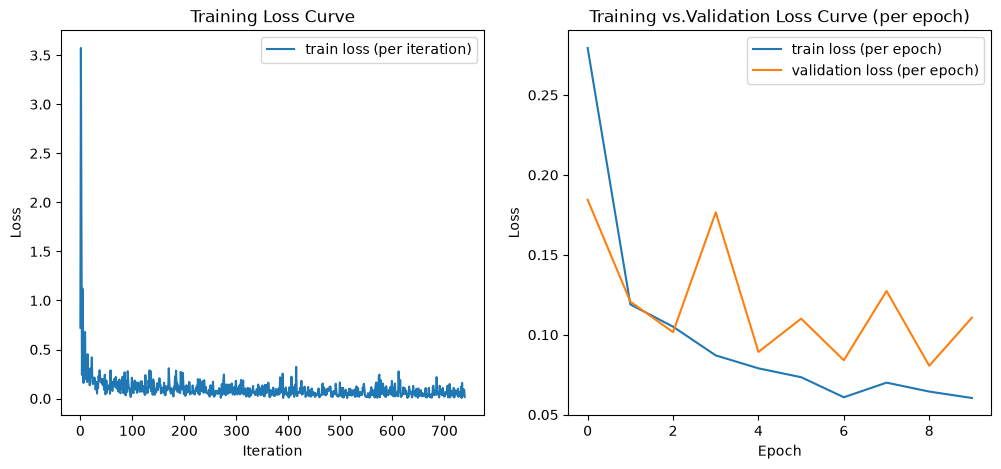

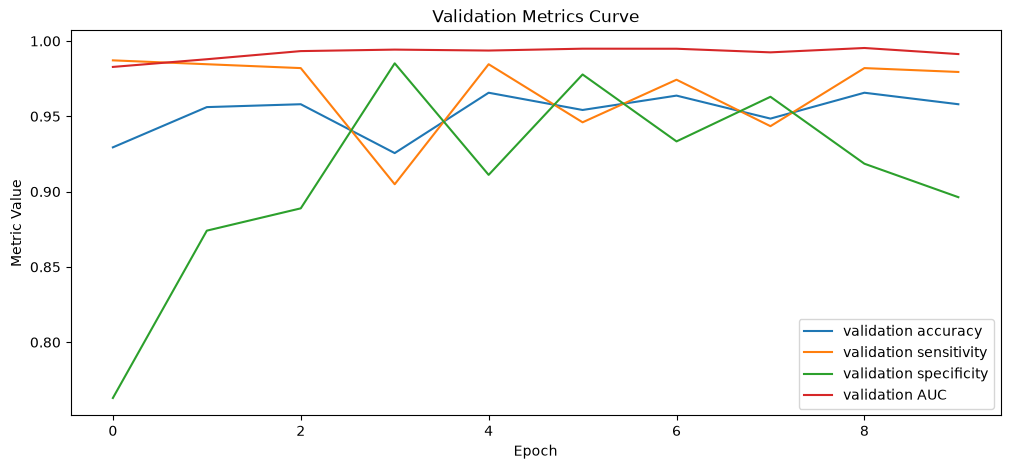

In [25]:
import matplotlib.pyplot as plt
%matplotlib inline

def plot_history(history, title=''):
    ################################################################################
    # TODO: Plot the loss curves and the validation metrics.                       #
    ################################################################################
    # *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

    plt.figure(figsize=(12,5))
    plt.subplot(1,2,1)
    plt.plot(history['train_loss_iter'],label='train loss (per iteration)')
    plt.xlabel('Iteration')
    plt.ylabel('Loss')
    plt.title('Training Loss Curve')
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(history['train_loss'],label='train loss (per epoch)')
    plt.plot(history['val_loss'],label='validation loss (per epoch)')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training vs.Validation Loss Curve (per epoch)')
    plt.legend()


    plt.figure(figsize=(12,5))
    plt.plot(history['val_accuracy'],label='validation accuracy')
    plt.plot(history['val_sensitivity'],label='validation sensitivity')
    plt.plot(history['val_specificity'],label='validation specificity')
    plt.plot(history['val_auc'],label='validation AUC')
    plt.xlabel('Epoch')
    plt.ylabel('Metric Value')
    plt.title('Validation Metrics Curve')
    plt.legend()
    plt.show()
    # *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
    ################################################################################
    #                                 END OF YOUR CODE                             #
    ################################################################################

plot_history(history_baseline, 'AdamW, constant learning rate 1e-2')

**Inline Question 1:** Analyse the curves of the baseline.
- How noisy is the training loss from iteration to iteration, and why?
- Does the validation loss follow the training loss? Is the model underfitting or overfitting, and from which epoch?
- Which epoch was selected as the best one, and how much better is it than the last epoch?
- Is the validation accuracy a good guide here? Compare it with the sensitivity, specificity and AUC.
- Based on the curves, would you increase or decrease the learning rate, and would you train for more or fewer epochs?

**Answer:**

### Learning-rate schedules

With a constant learning rate, the parameters keep jumping around the minimum once the loss stops decreasing: the step size that was useful at the start of training is too large at the end. A **learning-rate schedule** lowers the learning rate during training. Common schedules are:

- **Step decay** (`optim.lr_scheduler.StepLR`): multiply the learning rate by e.g. 0.1 every few epochs.
- **Cosine annealing** (`optim.lr_scheduler.CosineAnnealingLR`): decrease the learning rate smoothly from its initial value to (almost) zero along a cosine curve over the whole training run. This is the most common choice today.
- **Warm-up**: start with a small learning rate and increase it during the first iterations, which stabilizes the start of training (used for transformers and with large batch sizes). `optim.lr_scheduler.OneCycleLR` combines warm-up and annealing.
- **Reduce on plateau** (`optim.lr_scheduler.ReduceLROnPlateau`): lower the learning rate when the validation loss stops improving.

See [How to adjust the learning rate](https://docs.pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate) for all schedulers. In `train_part5`, the scheduler is stepped once per **epoch**, so set its length in epochs (for example `T_max=epochs` for cosine annealing).

Train the same model as the baseline, with the same seed and optimizer settings, but now with a cosine annealing schedule. Plot the history, and also compare the validation loss and AUC of the two runs in one plot.

In [26]:
history_cosine = None
################################################################################
# TODO: Train small_convnet() with AdamW and a cosine annealing schedule,      #
# then plot the history and compare the two runs.                              #
################################################################################
# *****START OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****

scheduler_cosine=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=epochs)
history_cosine=train_part5(model,optimizer,epochs=epochs,scheduler=scheduler_cosine,save_path='cosine.pt')

# *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
################################################################################
#                                 END OF YOUR CODE                             #
################################################################################

Epoch  1/10: train loss 0.0599, val loss 0.0789, val accuracy 96.76%, sensitivity 98.46%, specificity 91.85%, AUC 0.9953
Epoch  2/10: train loss 0.0478, val loss 0.0731, val accuracy 96.76%, sensitivity 97.69%, specificity 94.07%, AUC 0.9961
Epoch  3/10: train loss 0.0377, val loss 0.1194, val accuracy 95.80%, sensitivity 95.37%, specificity 97.04%, AUC 0.9944
Epoch  4/10: train loss 0.0256, val loss 0.0896, val accuracy 96.76%, sensitivity 97.94%, specificity 93.33%, AUC 0.9955
Epoch  5/10: train loss 0.0256, val loss 0.0933, val accuracy 96.56%, sensitivity 96.66%, specificity 96.30%, AUC 0.9952
Epoch  6/10: train loss 0.0175, val loss 0.0933, val accuracy 96.95%, sensitivity 98.20%, specificity 93.33%, AUC 0.9953
Epoch  7/10: train loss 0.0107, val loss 0.0908, val accuracy 96.95%, sensitivity 98.20%, specificity 93.33%, AUC 0.9954
Epoch  8/10: train loss 0.0078, val loss 0.0898, val accuracy 97.14%, sensitivity 97.94%, specificity 94.81%, AUC 0.9956
Epoch  9/10: train loss 0.0068, 

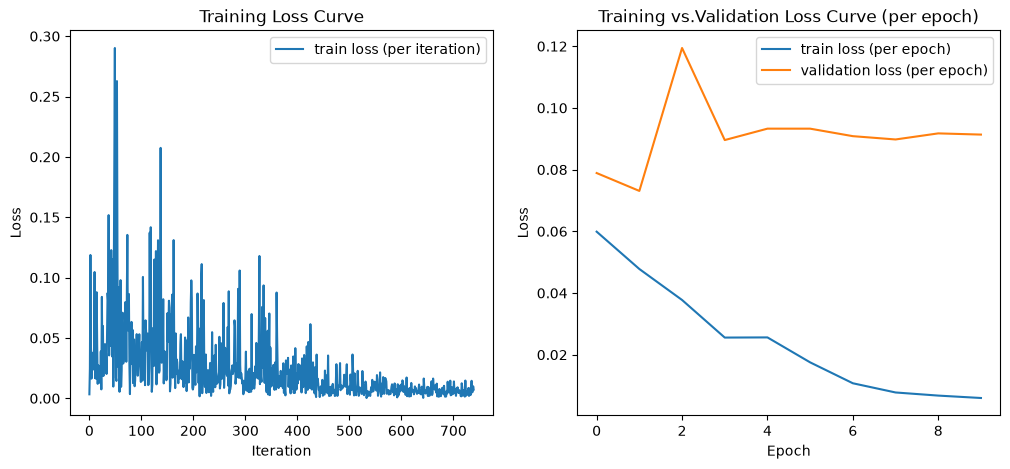

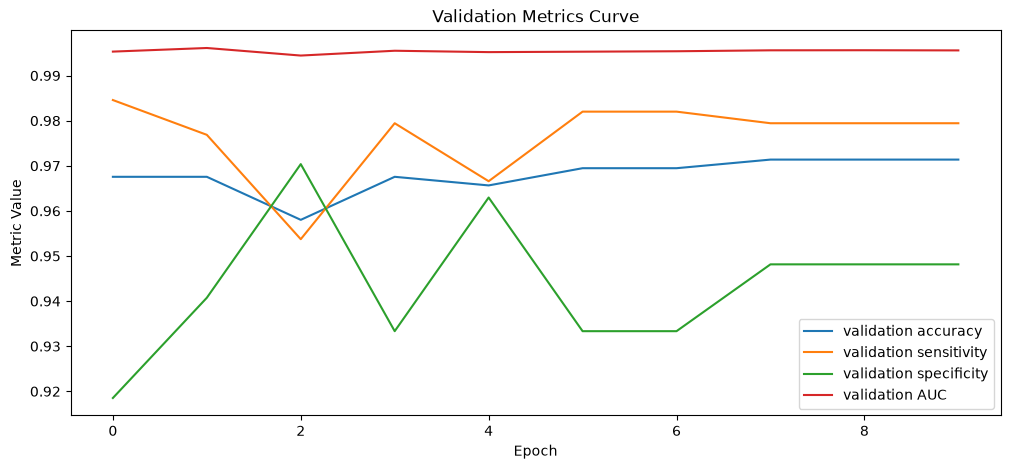

In [27]:
plot_history(history_cosine, 'AdamW, cosine annealing learning rate')

**Inline Question 2:** Compare the runs with and without the learning-rate schedule. How do the training loss curves differ towards the end of training? Which run reached the better validation loss and AUC, and in which epoch? Why do you think the schedule helps (or does not help) here?

**Answer:**

### Speed: mixed precision and `torch.compile`

Two features make training on a GPU faster with little effort:

- **Automatic mixed precision** (`use_amp=True` in `train_part5`): runs most operations in 16-bit floating point. On GPUs with tensor cores (on MAIA: the RTX 2080 Ti and RTX 3080) this is often 2-3 times faster for larger models; older GPUs such as the GTX 1070 / 1080 Ti have no tensor cores and gain little. Newer GPUs also support `bfloat16`, which does not need a `GradScaler`.
- **`torch.compile(model)`**: compiles the model into optimized GPU kernels the first time it runs. The first epoch is slower because of the compilation, the following ones are faster. It needs a GPU with compute capability 7.0 or newer (not the GTX 10xx cards) and works best for larger models and longer training runs.

For the small models in this lab the data loading and Python overhead dominate, so do not expect large gains. This part is optional: if you are on a GPU, you can time one epoch with and without mixed precision with the cell below.

In [28]:
# Optional: compare the time of training with and without mixed precision (NVIDIA GPU only).
import time
if device.type == 'cuda':
    for amp in [False, True]:
        set_seed(0)
        model = small_convnet()
        optimizer = optim.AdamW(model.parameters(), lr=1e-3)
        t0 = time.time()
        train_part5(model, optimizer, epochs=2, use_amp=amp, save_path='amp_test.pt')
        torch.cuda.synchronize()
        print('use_amp=%s: %.1f s\n' % (amp, time.time() - t0))
else:
    print('Mixed precision is only used on NVIDIA GPUs; skipping.')

Mixed precision is only used on NVIDIA GPUs; skipping.


# Part VI. PneumoniaMNIST open-ended challenge

In this section, you can experiment with whatever ConvNet architecture you'd like on the dataset.

Now it's your job to experiment with architectures, hyperparameters, loss functions, optimizers and learning-rate schedules to train a model that achieves **at least 96% accuracy and a validation AUC of at least 0.995** on the **validation** set within 15 epochs. Train your models with `train_part5` from Part V and plot their history with your `plot_history` function. You can use either the `nn.Module` or the `nn.Sequential` API.

At the end of this notebook, describe what you did and analyse the loss curves of your final model.

Here are the official API documentation for each component. One note: what we call in the class "spatial batch norm" is called `BatchNorm2d` in PyTorch.

* Layers in torch.nn package: https://docs.pytorch.org/docs/stable/nn.html
* Activations: https://docs.pytorch.org/docs/stable/nn.html#non-linear-activations-weighted-sum-nonlinearity
* Loss functions: https://docs.pytorch.org/docs/stable/nn.html#loss-functions
* Optimizers: https://docs.pytorch.org/docs/stable/optim.html


### Things you might try:
- **Filter size**: Above we used 5x5; would smaller filters be more efficient?
- **Number of filters**: Above we used 32 filters. Do more or fewer do better?
- **Pooling vs Strided Convolution**: Do you use max pooling or just strided convolutions?
- **Batch normalization**: Try adding spatial batch normalization after convolution layers and vanilla batch normalization after affine layers. Do your networks train faster?
- **Network architecture**: The network above has three layers of trainable parameters. Can you do better with a deeper network? Good architectures to try include:
    - [conv-relu-pool]xN -> [affine]xM
    - [conv-relu-conv-relu-pool]xN -> [affine]xM
    - [batchnorm-relu-conv]xN -> [affine]xM
- **Global Average Pooling**: Instead of flattening and then having multiple affine layers, perform convolutions until your image gets small (7x7 or so) and then perform an average pooling operation to get to a 1x1 image (1, 1, Filter#), which is then reshaped into a (Filter#) vector (`nn.AdaptiveAvgPool2d(1)` does this for you). This is used in [Google's Inception Network](https://arxiv.org/abs/1512.00567) (See Table 1 for their architecture).
- **Regularization**: Add L2 weight regularization (`weight_decay` in the optimizer), or perhaps use Dropout.
- **Learning-rate schedule**: Use what you learned in Part V; the learning rate is usually the most important hyperparameter to tune.
- **Class imbalance**: About 74% of the training images show pneumonia. The `pos_weight` argument of `F.binary_cross_entropy_with_logits` lets you weigh the two classes differently.

### Tips for training
For each network architecture that you try, you should tune the learning rate and other hyperparameters. When doing this there are a couple important things to keep in mind:

- If the parameters are working well, you should see improvement within a few hundred iterations
- Remember the coarse-to-fine approach for hyperparameter tuning: start by testing a large range of hyperparameters for just a few training iterations to find the combinations of parameters that are working at all.
- Once you have found some sets of parameters that seem to work, search more finely around these parameters. You may need to train for more epochs.
- You should use the validation set for hyperparameter search, and save your test set for evaluating your architecture on the best parameters as selected by the validation set.

### Going above and beyond
If you are feeling adventurous there are many other features you can implement to try and improve your performance. You are **not required** to implement any of these, but don't miss the fun if you have time!

- Alternative optimizers: you can try SGD with momentum, Adam, RMSprop, etc.
- Alternative activation functions such as leaky ReLU, parametric ReLU, ELU or GELU.
- Data augmentation (for example small random rotations and shifts with `T.RandomAffine`); think about which augmentations make sense for chest X-rays.
- Choosing the decision threshold: `binary_metrics` uses 0.5. Which threshold would you pick for a screening tool where missing pneumonia is worse than a false alarm? (Choose it on the validation set!)
- Mixed precision training and `torch.compile` (see Part V) for larger models.
- Model ensembles
- New Architectures
  - [ResNets](https://arxiv.org/abs/1512.03385) where the input from the previous layer is added to the output.
  - [DenseNets](https://arxiv.org/abs/1608.06993) where inputs into previous layers are concatenated together.

### Have fun and happy training!

Epoch  1/15: train loss 0.1654, val loss 0.1118, val accuracy 95.23%, sensitivity 97.94%, specificity 87.41%, AUC 0.9915
Epoch  2/15: train loss 0.0978, val loss 0.0906, val accuracy 96.56%, sensitivity 97.17%, specificity 94.81%, AUC 0.9941
Epoch  3/15: train loss 0.0708, val loss 0.1294, val accuracy 95.23%, sensitivity 99.23%, specificity 83.70%, AUC 0.9934
Epoch  4/15: train loss 0.0597, val loss 0.1503, val accuracy 95.23%, sensitivity 93.83%, specificity 99.26%, AUC 0.9947
Epoch  5/15: train loss 0.0472, val loss 0.1086, val accuracy 95.23%, sensitivity 98.97%, specificity 84.44%, AUC 0.9949
Epoch  6/15: train loss 0.0416, val loss 0.2530, val accuracy 90.84%, sensitivity 87.66%, specificity 100.00%, AUC 0.9958
Epoch  7/15: train loss 0.0269, val loss 0.1712, val accuracy 94.85%, sensitivity 93.32%, specificity 99.26%, AUC 0.9956
Epoch  8/15: train loss 0.0222, val loss 0.1083, val accuracy 96.56%, sensitivity 99.49%, specificity 88.15%, AUC 0.9952
Epoch  9/15: train loss 0.0137,

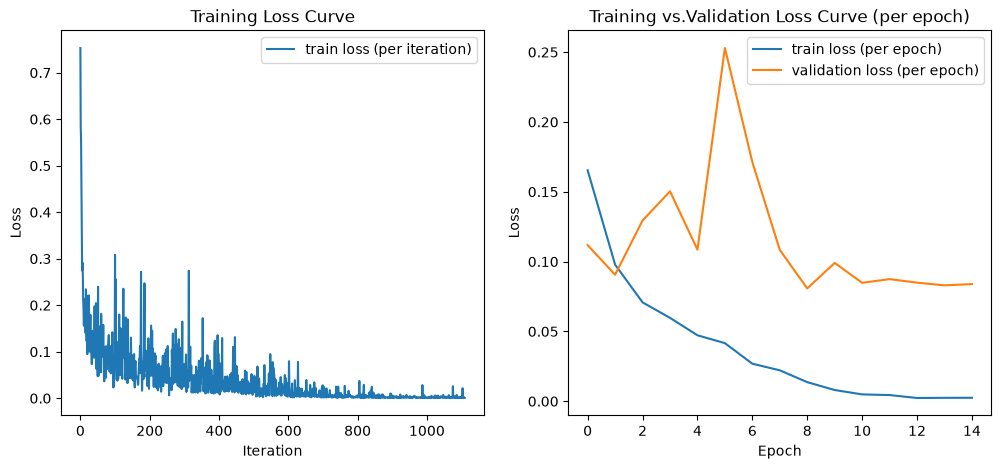

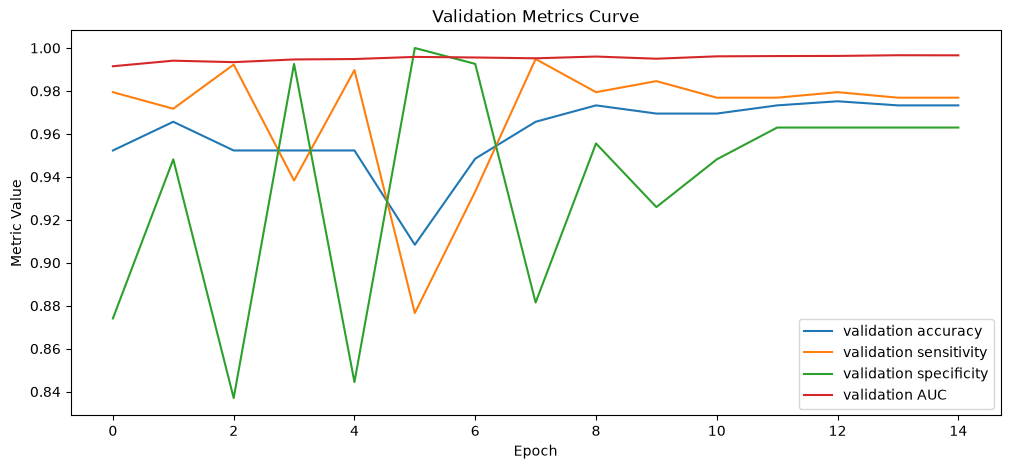

In [44]:
################################################################################
# TODO:                                                                        #
# Experiment with any architectures, optimizers, and hyperparameters.          #
# Achieve AT LEAST 96% accuracy and 0.995 AUC on the *validation set*          #
# within 15 epochs, using train_part5. Plot the history with plot_history.     #
#                                                                              #
# You should not touch the test set until you have finished your               #
# architecture and hyperparameter tuning, and only run the test set once at    #
# the end to report a final value.                                             #
################################################################################
set_seed(0)
model = None
optimizer = None
scheduler = None
epochs = 15

    
model = nn.Sequential( nn.Conv2d(1,32,7,padding=3), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2), #32 x 14 x 14
                       nn.Conv2d(32,64,7,padding=3), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2), #64 x 7 x 7
                       nn.Flatten(),
                       nn.Linear(64*7*7,1)
                     )

# architecture 2: [conv-relu-pool]xN -> [affine]xM, where N=2 and M=2
model = nn.Sequential( nn.Conv2d(1,32,7,padding=3), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2), #32 x 14 x 14
                       nn.Conv2d(32,64,7,padding=3), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2), #64 x 7 x 7
                       nn.Flatten(),
                       nn.Linear(64*7*7,128), nn.BatchNorm1d(128), nn.ReLU(), #vanilla batch normalization
                       nn.Linear(128,1)
                     )

optimizer=optim.RMSprop(model.parameters(),lr=1e-3,weight_decay=1e-4)
# optimizer=optim.AdamW(model.parameters(),lr=1e-3,weight_decay=1e-4)
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=epochs)


# *****END OF YOUR CODE (DO NOT DELETE/MODIFY THIS LINE)*****
################################################################################
#                                 END OF YOUR CODE                             #
################################################################################

# You may set epochs to any number up to 15.
history = train_part5(model, optimizer, epochs=epochs, scheduler=scheduler)
plot_history(history, 'Final model')

## Describe what you did

In the cell below you should write an explanation of what you did, any additional features that you implemented, and/or any graphs that you made in the process of training and evaluating your network. Analyse the loss curves of your final model: is it underfitting or overfitting, which epoch was selected, and what did the learning-rate schedule do?

**Answer:**
1. Numbers of filters 16 in first layer and 32 in the second layer (epochs=15). The optimizer is optimizer=optim.RMSprop(model.parameters(),lr=1e-3,weight_decay=1e-4). The learning-rate scheduler is the cosine annealing -- results: Loaded the weights of the best epoch (4, validation AUC 0.9966), also saved in best_model.pt | Epoch  4/15: train loss 0.0678, val loss 0.0771, val accuracy 96.95%, sensitivity 97.17%, specificity 96.30%, AUC 0.9966
2. Increased number of filters from 16 to 32 in first layer and from 32 to 64 in the second layer (epochs=15). The optimizer is optimizer=optim.RMSprop(model.parameters(),lr=1e-3,weight_decay=1e-4). The learning-rate scheduler is the cosine annealing -- results: Loaded the weights of the best epoch (13, validation AUC 0.9963), also saved in best_model.pt | Epoch 13/15: train loss 0.0278, val loss 0.0722, val accuracy 96.95%, sensitivity 97.43%, specificity 95.56%, AUC 0.9963
3. Same as in 2 but filter size changed to 7 (epochs=15) -- results: Loaded the weights of the best epoch (10, validation AUC 0.9965), also saved in best_model.pt | Epoch 10/15: train loss 0.0292, val loss 0.0754, val accuracy 97.14%, sensitivity 97.43%, specificity 96.30%, AUC 0.9965
4. As in 3 but optimizer=optim.AdamW(model.parameters(),lr=1e-3,weight_decay=1e-4) -- results: Loaded the weights of the best epoch (7, validation AUC 0.9959), also saved in best_model.pt | Epoch  7/15: train loss 0.0321, val loss 0.0830, val accuracy 96.95%, sensitivity 96.92%, specificity 97.04%, AUC 0.9959
5. Same as in 4 but with architecture 2: [conv-relu-pool]xN -> [affine]xM, where N=2 and M=2 -- results: Loaded the weights of the best epoch (12, validation AUC 0.9964), also saved in best_model.pt | Epoch 12/15: train loss 0.0213, val loss 0.0790, val accuracy 96.56%, sensitivity 97.43%, specificity 94.07%, AUC 0.9964
6. Same as 5 but with Vanilla batch normalization -- results: Loaded the weights of the best epoch (14, validation AUC 0.9966), also saved in best_model.pt | Epoch 14/15: train loss 0.0025, val loss 0.0830, val accuracy 97.33%, sensitivity 97.69%, specificity 96.30%, AUC 0.9966
7. Same as in 6 but learning rate increased to 1e-2 -- results: Loaded the weights of the best epoch (12, validation AUC 0.9954), also saved in best_model.pt | Epoch 12/15: train loss 0.0255, val loss 0.0938, val accuracy 97.71%, sensitivity 98.20%, specificity 96.30%, AUC 0.9954



## Test set -- run this only once

Now that we've gotten a result we're happy with, we test our final model on the test set. `train_part5` has already loaded the weights of the best epoch into `model`. Think about how the test results compare to your validation results. Note that the test set has a different class balance than the training and validation sets: 62.5% of the test images show pneumonia.

**Inline Question 3:** Compare the sensitivity and specificity on the test set with those on the validation set. What changed, and what could be the reason? What would this mean if the model were used in a hospital?

**Answer:**

In [ ]:
best_model = model  # train_part5 already loaded the weights of the best epoch
test_loss, test_probs, test_labels = evaluate(loader_test, best_model)
test_metrics = binary_metrics(test_probs, test_labels)
print('Test loss %.4f, accuracy %.2f%%, sensitivity %.2f%%, specificity %.2f%%, AUC %.4f'
      % (test_loss, 100 * test_metrics['accuracy'], 100 * test_metrics['sensitivity'],
         100 * test_metrics['specificity'], test_metrics['auc']))